In [11]:
import os

print(os.listdir("/kaggle/input"))

['datasets']


In [12]:
import os

print(os.listdir("/kaggle/input/datasets"))

['mateuszbuda']


In [13]:
import os

base_path = "/kaggle/input/datasets/mateuszbuda"
print(os.listdir(base_path))

['lgg-mri-segmentation']


In [14]:
import os

base_path = "/kaggle/input/datasets/mateuszbuda/lgg-mri-segmentation"
print(os.listdir(base_path))


['kaggle_3m', 'lgg-mri-segmentation']


In [15]:
import os

base_path = "/kaggle/input/datasets/mateuszbuda/lgg-mri-segmentation/kaggle_3m"
print(os.listdir(base_path)[:10])

['TCGA_DU_7010_19860307', 'TCGA_DU_8162_19961029', 'TCGA_FG_A4MT_20020212', 'TCGA_FG_5964_20010511', 'TCGA_DU_A5TS_19970726', 'TCGA_HT_7692_19960724', 'TCGA_DU_5849_19950405', 'TCGA_FG_A60K_20040224', 'TCGA_HT_7475_19970918', 'TCGA_FG_6691_20020405']


In [16]:
import os
import cv2
import torch
import numpy as np

base_path = "/kaggle/input/datasets/mateuszbuda/lgg-mri-segmentation/kaggle_3m"

image_paths = []
mask_paths = []

total_images_scanned = 0
missing_masks = 0

for folder in os.listdir(base_path):
    folder_path = os.path.join(base_path, folder)

    if not os.path.isdir(folder_path):
        continue

    for file in os.listdir(folder_path):

        # take only image files
        if file.endswith(".tif") and "_mask" not in file:

            total_images_scanned += 1

            img_path = os.path.join(folder_path, file)

            # expected mask name
            mask_name = file.replace(".tif", "_mask.tif")
            mask_path = os.path.join(folder_path, mask_name)

            # keep only valid pairs
            if os.path.exists(mask_path):
                image_paths.append(img_path)
                mask_paths.append(mask_path)
            else:
                missing_masks += 1

# ------------------ DEBUG INFO ------------------
print("Total valid image-mask pairs:", len(image_paths))
print("Images without masks:", missing_masks)
print("Total images scanned:", total_images_scanned)

# sanity check (optional but good)
assert len(image_paths) == len(mask_paths), "Mismatch between images and masks!"

Total valid image-mask pairs: 3929
Images without masks: 0
Total images scanned: 3929


In [19]:
from torch.utils.data import Dataset
import cv2
import numpy as np
import torch

class LGGDataset(Dataset):
    def __init__(self, image_paths, mask_paths, img_size=256):
        self.image_paths = image_paths
        self.mask_paths = mask_paths
        self.img_size = img_size

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):

        # ---------------- IMAGE ----------------
        img = cv2.imread(self.image_paths[idx])

        if img is None:
            raise ValueError(f"Image not found: {self.image_paths[idx]}")

        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img = cv2.resize(img, (self.img_size, self.img_size))

        img = img.astype(np.float32) / 255.0
        img = np.transpose(img, (2, 0, 1))  # HWC → CHW

        # ✅ FIX 1: proper float tensor conversion
        img = torch.from_numpy(img).float()

        # ---------------- MASK ----------------
        mask = cv2.imread(self.mask_paths[idx], cv2.IMREAD_GRAYSCALE)

        if mask is None:
            raise ValueError(f"Mask not found: {self.mask_paths[idx]}")

        mask = cv2.resize(mask, (self.img_size, self.img_size))

        # binarize mask properly
        mask = (mask > 0).astype(np.float32)

        # ✅ FIX 2: proper float tensor conversion + channel dimension
        mask = torch.from_numpy(mask).float().unsqueeze(0)  # [1, H, W]

        return img, mask

In [20]:
dataset = LGGDataset(image_paths, mask_paths)

img, mask = dataset[0]

print(img.min(), img.max())
print(mask.min(), mask.max())

tensor(0.) tensor(0.9059)
tensor(0.) tensor(1.)


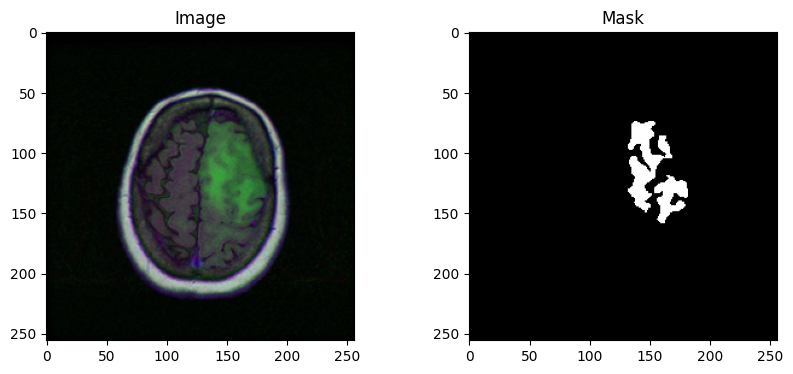

In [22]:
import numpy as np
import matplotlib.pyplot as plt

img_np = img.permute(1, 2, 0).numpy()
mask_np = mask.squeeze().numpy()

# ✔ apply clipping AFTER conversion
img_np = np.clip(img_np, 0, 1)

plt.figure(figsize=(10,4))

plt.subplot(1,2,1)
plt.imshow(img_np)
plt.title("Image")

plt.subplot(1,2,2)
plt.imshow(mask_np, cmap='gray')
plt.title("Mask")

plt.show()

In [23]:
from sklearn.model_selection import train_test_split

train_img, temp_img, train_mask, temp_mask = train_test_split(
    image_paths, mask_paths, test_size=0.3, random_state=42
)

val_img, test_img, val_mask, test_mask = train_test_split(
    temp_img, temp_mask, test_size=0.5, random_state=42
)

In [24]:
train_dataset = LGGDataset(train_img, train_mask)
val_dataset   = LGGDataset(val_img, val_mask)
test_dataset  = LGGDataset(test_img, test_mask)

In [25]:
from torch.utils.data import DataLoader

train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True)
val_loader   = DataLoader(val_dataset, batch_size=8, shuffle=False)
test_loader  = DataLoader(test_dataset, batch_size=8, shuffle=False)

In [26]:
import torch
import torch.nn as nn

class DoubleConv(nn.Module):
    def __init__(self, in_ch, out_ch, dropout=0.1):
        super(DoubleConv, self).__init__()

        self.conv = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),

            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),

            nn.Dropout(dropout)  # IMPORTANT for medical datasets
        )

    def forward(self, x):
        return self.conv(x)

In [28]:
class UNet(nn.Module):
    def __init__(self):
        super(UNet, self).__init__()

        # Encoder
        self.enc1 = DoubleConv(3, 64)
        self.pool1 = nn.MaxPool2d(2)

        self.enc2 = DoubleConv(64, 128)
        self.pool2 = nn.MaxPool2d(2)

        self.enc3 = DoubleConv(128, 256)
        self.pool3 = nn.MaxPool2d(2)

        self.enc4 = DoubleConv(256, 512)
        self.pool4 = nn.MaxPool2d(2)

        # Bottleneck (with dropout)
        self.bottleneck = DoubleConv(512, 1024, dropout=0.2)

        # Decoder
        self.up4 = nn.ConvTranspose2d(1024, 512, 2, stride=2)
        self.dec4 = DoubleConv(1024, 512)

        self.up3 = nn.ConvTranspose2d(512, 256, 2, stride=2)
        self.dec3 = DoubleConv(512, 256)

        self.up2 = nn.ConvTranspose2d(256, 128, 2, stride=2)
        self.dec2 = DoubleConv(256, 128)

        self.up1 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.dec1 = DoubleConv(128, 64)

        # Output
        self.out = nn.Conv2d(64, 1, 1)

    def forward(self, x):

        # Encoder
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool1(e1))
        e3 = self.enc3(self.pool2(e2))
        e4 = self.enc4(self.pool3(e3))

        # Bottleneck
        b = self.bottleneck(self.pool4(e4))

        # Decoder
        d4 = self.up4(b)
        d4 = torch.cat([d4, e4], dim=1)
        d4 = self.dec4(d4)

        d3 = self.up3(d4)
        d3 = torch.cat([d3, e3], dim=1)
        d3 = self.dec3(d3)

        d2 = self.up2(d3)
        d2 = torch.cat([d2, e2], dim=1)
        d2 = self.dec2(d2)

        d1 = self.up1(d2)
        d1 = torch.cat([d1, e1], dim=1)
        d1 = self.dec1(d1)

        return self.out(d1)

In [35]:
class DiceBCELoss(nn.Module):
    def __init__(self):
        super().__init__()
        self.bce = nn.BCEWithLogitsLoss()

    def forward(self, pred, target):
        bce = self.bce(pred, target)

        pred = torch.sigmoid(pred)

        pred = pred.view(pred.size(0), -1)
        target = target.view(target.size(0), -1)

        intersection = (pred * target).sum(dim=1)

        dice = (2 * intersection + 1e-6) / (pred.sum(dim=1) + target.sum(dim=1) + 1e-6)

        dice_loss = 1 - dice.mean()

        return 0.5 * bce + 0.5 * dice_loss

In [36]:
model = UNet()

In [37]:
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

In [38]:
criterion = DiceBCELoss()

In [51]:
#BROKEN SOMETHING S WRONG 
best_val_loss = float("inf")
best_epoch = -1

for epoch in range(epochs):

    # ---------------- TRAIN ----------------
    model.train()
    train_loss = 0.0

    for imgs, masks in train_loader:

        imgs = imgs.to(device)
        masks = masks.to(device).float()

        outputs = model(imgs)
        loss = criterion(outputs, masks)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        train_loss += loss.item()

    avg_train_loss = train_loss / len(train_loader)

    # ---------------- VALIDATION ----------------
    model.eval()
    val_loss = 0.0

    with torch.no_grad():
        for imgs, masks in val_loader:

            imgs = imgs.to(device)
            masks = masks.to(device).float()

            outputs = model(imgs)
            outputs = torch.sigmoid(outputs)

            loss = criterion(outputs, masks)

            val_loss += loss.item()

    avg_val_loss = val_loss / len(val_loader)

    # ---------------- TRACK BEST ----------------
    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss
        best_epoch = epoch + 1
        torch.save(model.state_dict(), "best_model.pth")

    # ---------------- PRINT ----------------
    print(f"Epoch [{epoch+1}/{epochs}] | "
          f"Train Loss: {avg_train_loss:.4f} | "
          f"Val Loss: {avg_val_loss:.4f}")

print("\nBest Epoch:", best_epoch)
print("Best Val Loss:", best_val_loss)

Epoch [1/10] | Train Loss: 0.3794 | Val Loss: 0.8328
Epoch [2/10] | Train Loss: 0.3753 | Val Loss: 0.8327


KeyboardInterrupt: 

In [52]:
#CHECK ONE 
import numpy as np

# check a few samples from train dataset
for i in range(5):
    _, mask = train_dataset[i]

    print(f"Sample {i}")
    print("Unique values:", np.unique(mask))
    print("Min:", mask.min(), "Max:", mask.max())
    print("-" * 30)

Sample 0
Unique values: [0.]
Min: tensor(0.) Max: tensor(0.)
------------------------------
Sample 1
Unique values: [0. 1.]
Min: tensor(0.) Max: tensor(1.)
------------------------------
Sample 2
Unique values: [0.]
Min: tensor(0.) Max: tensor(0.)
------------------------------
Sample 3
Unique values: [0.]
Min: tensor(0.) Max: tensor(0.)
------------------------------
Sample 4
Unique values: [0.]
Min: tensor(0.) Max: tensor(0.)
------------------------------


In [53]:
#CHECK 2 
filtered_imgs = []
filtered_masks = []

for img, mask in zip(image_paths, mask_paths):

    m = np.array(mask)

    if np.sum(m) > 0:   # keeps only tumor slices
        filtered_imgs.append(img)
        filtered_masks.append(mask)

TypeError: the resolved dtypes are not compatible with add.reduce. Resolved (dtype('<U121'), dtype('<U121'), dtype('<U242'))

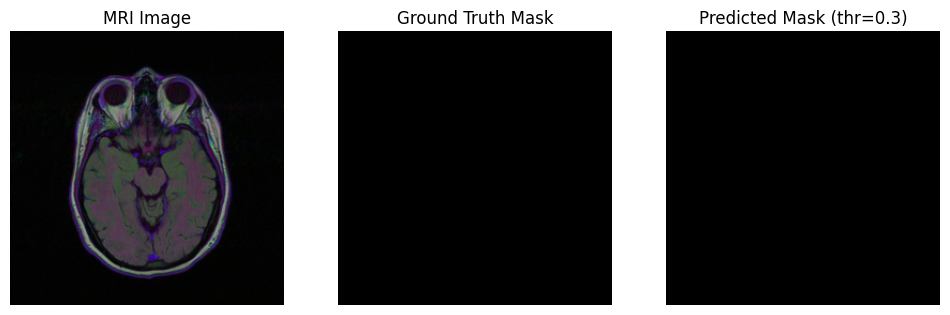

In [44]:
#VISUALISATION
import torch
import matplotlib.pyplot as plt
import numpy as np

model.eval()

# take one batch from test_loader
imgs, masks = next(iter(test_loader))

imgs = imgs.to(device)
masks = masks.to(device)

with torch.no_grad():
    outputs = model(imgs)
    preds = torch.sigmoid(outputs)

# move to CPU
imgs = imgs.cpu()
masks = masks.cpu()
preds = preds.cpu()

idx = 0  # you can change this to 1,2,3,...

img = imgs[idx].permute(1, 2, 0).numpy()
gt_mask = masks[idx].squeeze().numpy()
pred_mask = preds[idx].squeeze().numpy()

# ✔ LOWER threshold (important fix)
pred_mask_bin = (pred_mask > 0.3).astype(np.float32)

plt.figure(figsize=(12,4))

# MRI image
plt.subplot(1,3,1)
plt.imshow(img)
plt.title("MRI Image")
plt.axis("off")

# Ground truth
plt.subplot(1,3,2)
plt.imshow(gt_mask, cmap="gray")
plt.title("Ground Truth Mask")
plt.axis("off")

# Prediction
plt.subplot(1,3,3)
plt.imshow(pred_mask_bin, cmap="gray")
plt.title("Predicted Mask (thr=0.3)")
plt.axis("off")

plt.show()

In [45]:
np.unique(gt_mask)

array([0.], dtype=float32)

In [46]:
#TO LOCATE THE IMAGE WHERE THE REAL TUMOR IS THERE 
for i in range(len(test_dataset)):
    _, mask = test_dataset[i]
    if mask.sum() > 0:
        print("Tumor found at index:", i)
        break

Tumor found at index: 1


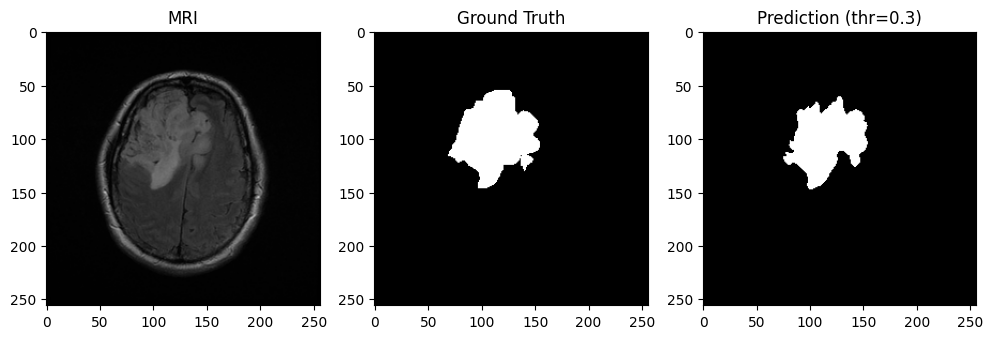

In [47]:
#GOT THE POSITION ,NOW VISUALISING IT 
idx = 1

imgs, masks = test_dataset[idx]
img = imgs.unsqueeze(0).to(device)

model.eval()
with torch.no_grad():
    output = model(img)
    pred = torch.sigmoid(output)

# move to cpu
img = img.cpu().squeeze().permute(1,2,0).numpy()
gt = masks.squeeze().numpy()
pred = pred.cpu().squeeze().numpy()

pred_bin = (pred > 0.3).astype(float)

import matplotlib.pyplot as plt

plt.figure(figsize=(12,4))

plt.subplot(1,3,1)
plt.imshow(img)
plt.title("MRI")

plt.subplot(1,3,2)
plt.imshow(gt, cmap="gray")
plt.title("Ground Truth")

plt.subplot(1,3,3)
plt.imshow(pred_bin, cmap="gray")
plt.title("Prediction (thr=0.3)")

plt.show()

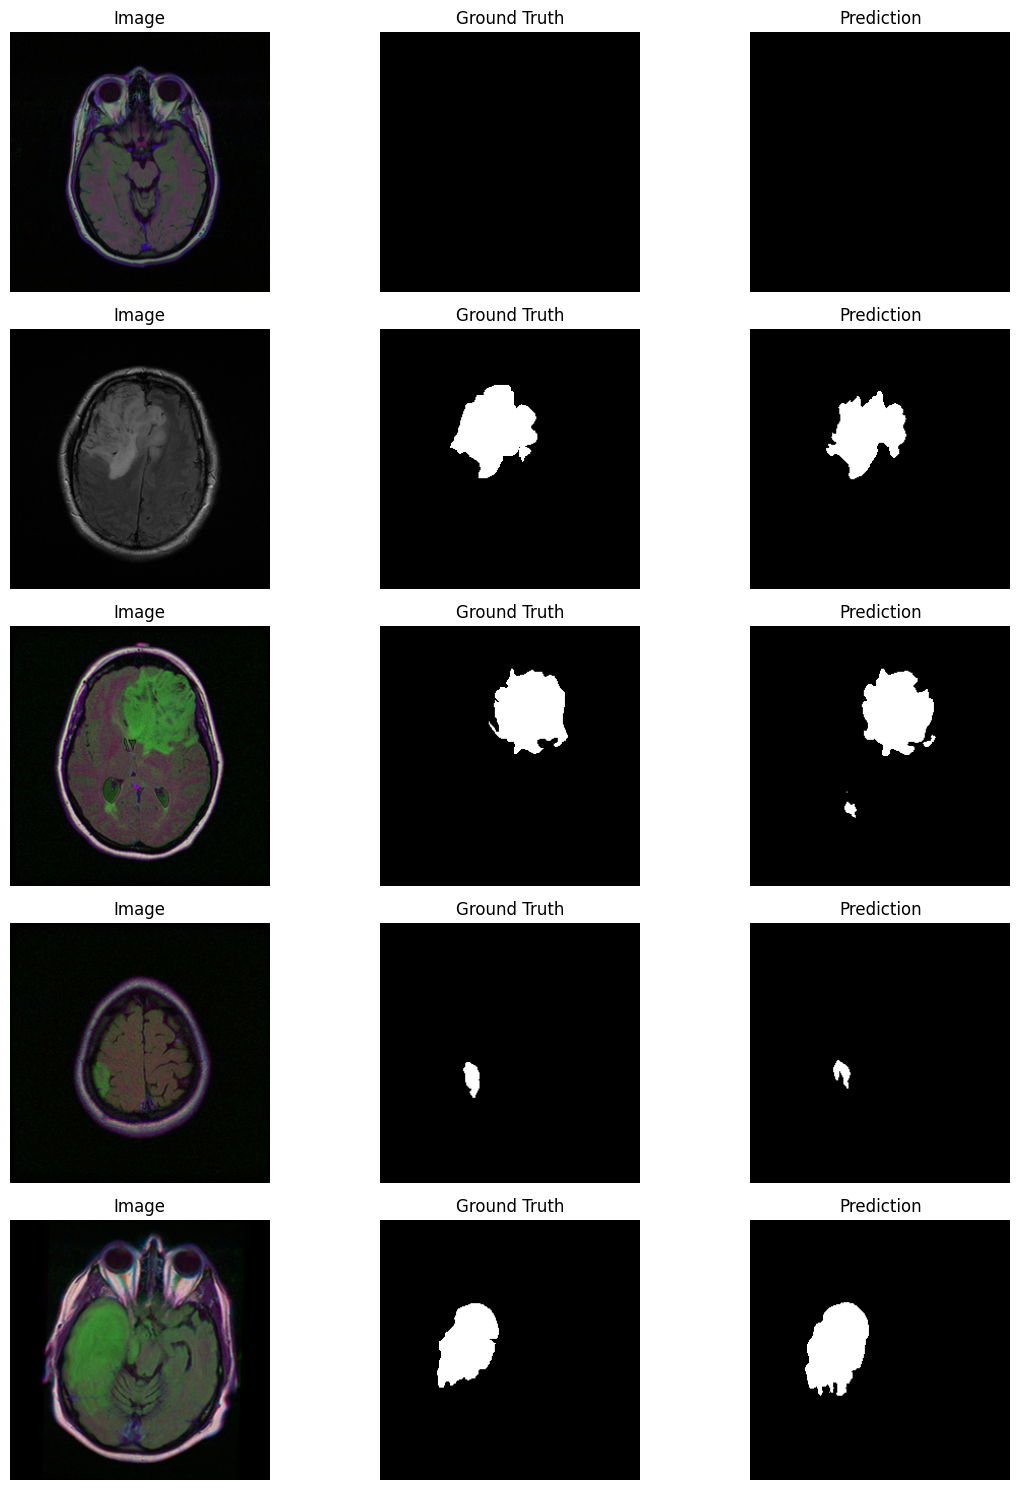

In [49]:
#For 5 MORE SAMPLES RUNNING THIS 
import torch
import matplotlib.pyplot as plt
import numpy as np

model.eval()

num_samples = 5  # change to 10 if you want more

plt.figure(figsize=(12, num_samples * 3))

for i in range(num_samples):

    # get sample from test dataset
    img, mask = test_dataset[i]

    img_input = img.unsqueeze(0).to(device)

    with torch.no_grad():
        output = model(img_input)
        pred = torch.sigmoid(output)

    # move to CPU
    img_np = img.permute(1, 2, 0).numpy()
    gt_np = mask.squeeze().numpy()
    pred_np = pred.squeeze().cpu().numpy()

    pred_bin = (pred_np > 0.3).astype(np.float32)

    # Plot
    plt.subplot(num_samples, 3, i*3 + 1)
    plt.imshow(img_np)
    plt.title("Image")
    plt.axis("off")

    plt.subplot(num_samples, 3, i*3 + 2)
    plt.imshow(gt_np, cmap="gray")
    plt.title("Ground Truth")
    plt.axis("off")

    plt.subplot(num_samples, 3, i*3 + 3)
    plt.imshow(pred_bin, cmap="gray")
    plt.title("Prediction")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [55]:
#FIX FILTERING CODE 
from PIL import Image
import numpy as np

filtered_imgs = []
filtered_masks = []

for img_path, mask_path in zip(image_paths, mask_paths):

    # load mask properly
    mask = np.array(Image.open(mask_path).convert("L"))

    # check tumor presence
    if mask.max() > 0:   # better than sum
        filtered_imgs.append(img_path)
        filtered_masks.append(mask_path)

print("Original:", len(image_paths))
print("Filtered:", len(filtered_imgs))

Original: 3929
Filtered: 1373


In [56]:
#REBUILD DATASET EARLIER FULL OF EMPTY NOW WE ARE CLEANING IT 
from sklearn.model_selection import train_test_split

train_img, temp_img, train_mask, temp_mask = train_test_split(
    filtered_imgs, filtered_masks, test_size=0.3, random_state=42
)

val_img, test_img, val_mask, test_mask = train_test_split(
    temp_img, temp_mask, test_size=0.5, random_state=42
)

In [57]:
#DATASET OBJECTS 
train_dataset = LGGDataset(train_img, train_mask)
val_dataset   = LGGDataset(val_img, val_mask)
test_dataset  = LGGDataset(test_img, test_mask)

In [58]:
#RESET DATALOADERS
from torch.utils.data import DataLoader

train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True)
val_loader   = DataLoader(val_dataset, batch_size=8, shuffle=False)
test_loader  = DataLoader(test_dataset, batch_size=8, shuffle=False)

In [59]:
#MOVE MODEL TO DEVICE
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = UNet().to(device)   # IMPORTANT: fresh model (NOT old weights)

optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

In [60]:
epochs = 10
best_val_loss = float("inf")

for epoch in range(epochs):

    # ---------------- TRAIN ----------------
    model.train()
    train_loss = 0.0

    for imgs, masks in train_loader:

        imgs = imgs.to(device)
        masks = masks.to(device).float()

        outputs = model(imgs)

        loss = criterion(outputs, masks)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        train_loss += loss.item()

    avg_train_loss = train_loss / len(train_loader)

    # ---------------- VALIDATION ----------------
    model.eval()
    val_loss = 0.0

    with torch.no_grad():
        for imgs, masks in val_loader:

            imgs = imgs.to(device)
            masks = masks.to(device).float()

            outputs = model(imgs)

            loss = criterion(outputs, masks)

            val_loss += loss.item()

    avg_val_loss = val_loss / len(val_loader)

    # ---------------- SAVE BEST MODEL ----------------
    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss
        torch.save(model.state_dict(), "best_model.pth")

    print(f"Epoch [{epoch+1}/{epochs}] | "
          f"Train Loss: {avg_train_loss:.4f} | "
          f"Val Loss: {avg_val_loss:.4f}")

Epoch [1/10] | Train Loss: 0.6284 | Val Loss: 0.5992
Epoch [2/10] | Train Loss: 0.5547 | Val Loss: 0.5315
Epoch [3/10] | Train Loss: 0.5103 | Val Loss: 0.4960
Epoch [4/10] | Train Loss: 0.4763 | Val Loss: 0.4631
Epoch [5/10] | Train Loss: 0.4359 | Val Loss: 0.4225
Epoch [6/10] | Train Loss: 0.4004 | Val Loss: 0.3883
Epoch [7/10] | Train Loss: 0.3664 | Val Loss: 0.3650
Epoch [8/10] | Train Loss: 0.3351 | Val Loss: 0.3403
Epoch [9/10] | Train Loss: 0.3012 | Val Loss: 0.2986
Epoch [10/10] | Train Loss: 0.2722 | Val Loss: 0.2715


In [61]:
model.load_state_dict(torch.load("best_model.pth"))
model.to(device)
model.eval()

UNet(
  (enc1): DoubleConv(
    (conv): Sequential(
      (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU(inplace=True)
      (6): Dropout(p=0.1, inplace=False)
    )
  )
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (enc2): DoubleConv(
    (conv): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(128, eps=1e-05, mome

In [62]:
model.eval()

smooth = 1e-6

dice_scores = []
iou_scores = []

with torch.no_grad():
    for imgs, masks in test_loader:

        imgs = imgs.to(device)
        masks = masks.to(device).float()

        outputs = model(imgs)

        preds = torch.sigmoid(outputs)
        preds = (preds > 0.5).float()

        preds = preds.view(preds.size(0), -1)
        masks = masks.view(masks.size(0), -1)

        intersection = (preds * masks).sum(dim=1)

        dice = (2. * intersection + smooth) / (preds.sum(dim=1) + masks.sum(dim=1) + smooth)

        union = preds.sum(dim=1) + masks.sum(dim=1) - intersection

        iou = (intersection + smooth) / (union + smooth)

        dice_scores.extend(dice.cpu().numpy())
        iou_scores.extend(iou.cpu().numpy())

mean_dice = np.mean(dice_scores)
mean_iou = np.mean(iou_scores)

print(f"Mean Dice Score: {mean_dice:.4f}")
print(f"Mean IoU Score: {mean_iou:.4f}")

Mean Dice Score: 0.7783
Mean IoU Score: 0.6728


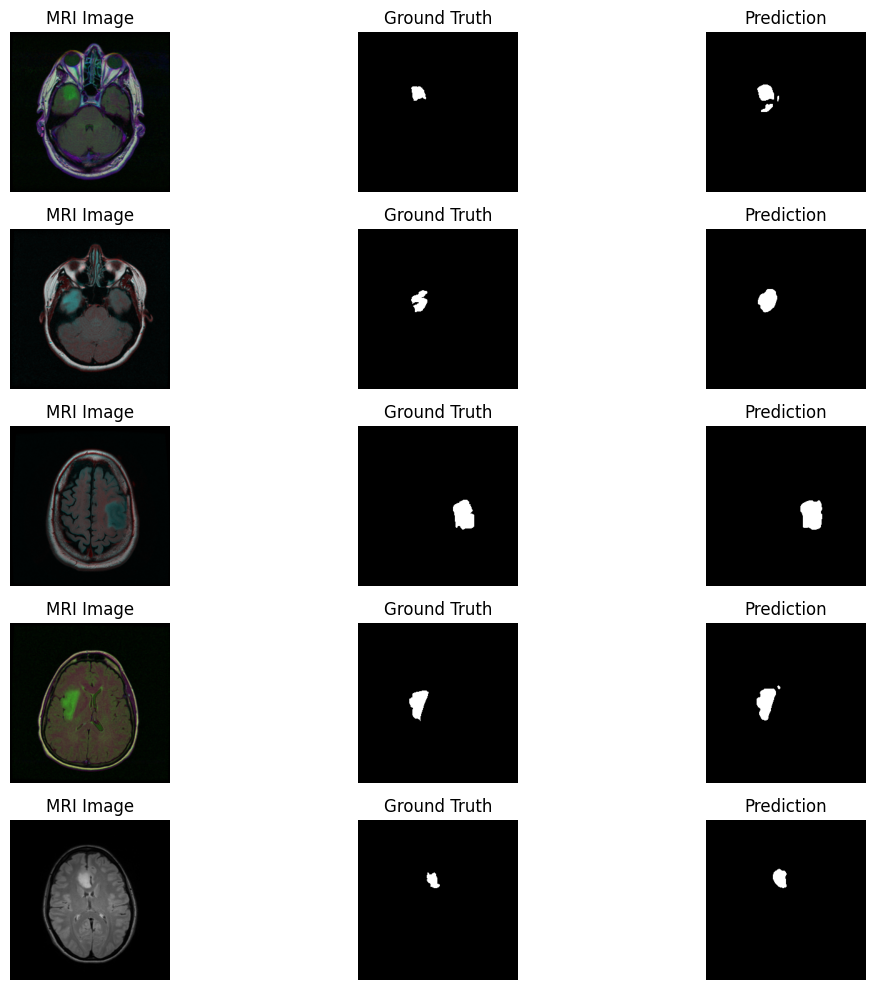

In [63]:
import matplotlib.pyplot as plt
import torch

model.eval()

with torch.no_grad():
    imgs, masks = next(iter(test_loader))  # take one batch

    imgs = imgs.to(device)
    masks = masks.to(device).float()

    outputs = model(imgs)
    preds = torch.sigmoid(outputs)
    preds = (preds > 0.5).float()

# move to CPU for plotting
imgs = imgs.cpu()
masks = masks.cpu()
preds = preds.cpu()

n = 5  # number of samples

plt.figure(figsize=(12, 10))

for i in range(n):

    # MRI Image
    plt.subplot(n, 3, i*3 + 1)
    img = imgs[i].permute(1, 2, 0).numpy()
    plt.imshow(img)
    plt.title("MRI Image")
    plt.axis("off")

    # Ground Truth
    plt.subplot(n, 3, i*3 + 2)
    gt = masks[i].squeeze().numpy()
    plt.imshow(gt, cmap="gray")
    plt.title("Ground Truth")
    plt.axis("off")

    # Prediction
    plt.subplot(n, 3, i*3 + 3)
    pred = preds[i].squeeze().numpy()
    plt.imshow(pred, cmap="gray")
    plt.title("Prediction")
    plt.axis("off")

plt.tight_layout()
plt.show()

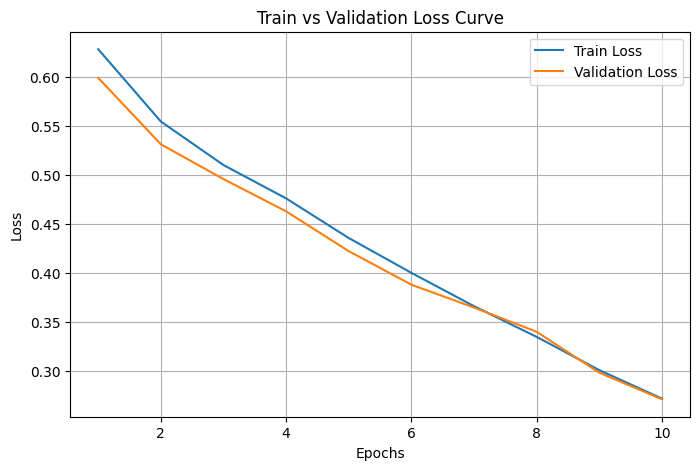

In [64]:
import matplotlib.pyplot as plt

epochs = list(range(1, 11))

train_losses = [0.6284, 0.5547, 0.5103, 0.4763, 0.4359, 
                0.4004, 0.3664, 0.3351, 0.3012, 0.2722]

val_losses = [0.5992, 0.5315, 0.4960, 0.4631, 0.4225, 
              0.3883, 0.3650, 0.3403, 0.2986, 0.2715]

plt.figure(figsize=(8,5))

plt.plot(epochs, train_losses, label="Train Loss")
plt.plot(epochs, val_losses, label="Validation Loss")

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Train vs Validation Loss Curve")
plt.legend()
plt.grid(True)

plt.show()

In [85]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

activations = []
gradients = []

def forward_hook(module, input, output):
    activations.clear()
    activations.append(output)

def backward_hook(module, grad_in, grad_out):
    gradients.clear()
    gradients.append(grad_out[0])

# attach to encoder layer
target_layer = model.enc4
target_layer.register_forward_hook(forward_hook)
target_layer.register_full_backward_hook(backward_hook)

In [86]:
model.eval()

imgs, masks = next(iter(test_loader))

img = imgs[0].unsqueeze(0).to(device)
img.requires_grad = True

In [87]:
output = model(img)
pred = torch.sigmoid(output)

In [88]:
model.zero_grad()

score = pred.mean()   # stable Grad-CAM signal
score.backward()

In [89]:
grads = gradients[0]
acts = activations[0]

weights = torch.mean(grads, dim=(2, 3), keepdim=True)
cam = torch.sum(weights * acts, dim=1)

cam = F.relu(cam)

# normalize
cam = cam - cam.min()
cam = cam / (cam.max() + 1e-8)

# resize to input image size
cam = F.interpolate(
    cam.unsqueeze(0),
    size=img.shape[-2:],
    mode='bilinear',
    align_corners=False
)

cam = cam.squeeze().detach().cpu().numpy()

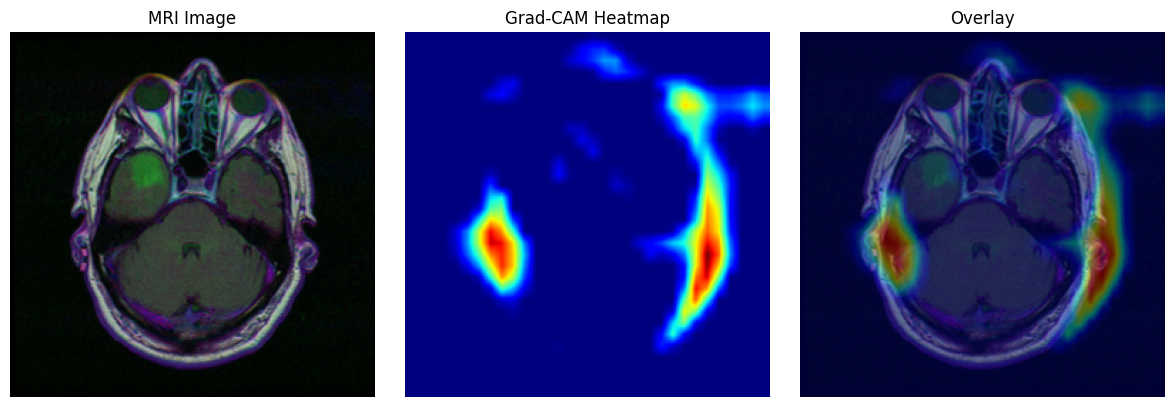

In [90]:
img_np = img.squeeze().detach().cpu().permute(1, 2, 0).numpy()

plt.figure(figsize=(12,4))

plt.subplot(1,3,1)
plt.imshow(img_np)
plt.title("MRI Image")
plt.axis("off")

plt.subplot(1,3,2)
plt.imshow(cam, cmap="jet")
plt.title("Grad-CAM Heatmap")
plt.axis("off")

plt.subplot(1,3,3)
plt.imshow(img_np)
plt.imshow(cam, cmap="jet", alpha=0.4)
plt.title("Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()

In [93]:
#####Trying only if it succedds then do or then dont 
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt

In [94]:
model.eval()

imgs, masks = next(iter(test_loader))

img = imgs[0].unsqueeze(0).to(device)

In [95]:
with torch.no_grad():
    base_output = torch.sigmoid(model(img))
    base_score = base_output.mean().item()

In [96]:
patch_size = 16
stride = 16

heatmap = np.zeros((img.shape[2], img.shape[3]))

In [97]:
img_np = img.squeeze().cpu().clone()

for i in range(0, img.shape[2], stride):
    for j in range(0, img.shape[3], stride):

        occluded = img_np.clone()

        occluded[:, i:i+patch_size, j:j+patch_size] = 0

        occluded = occluded.unsqueeze(0).to(device)

        with torch.no_grad():
            output = torch.sigmoid(model(occluded))
            score = output.mean().item()

        heatmap[i:i+patch_size, j:j+patch_size] = base_score - score

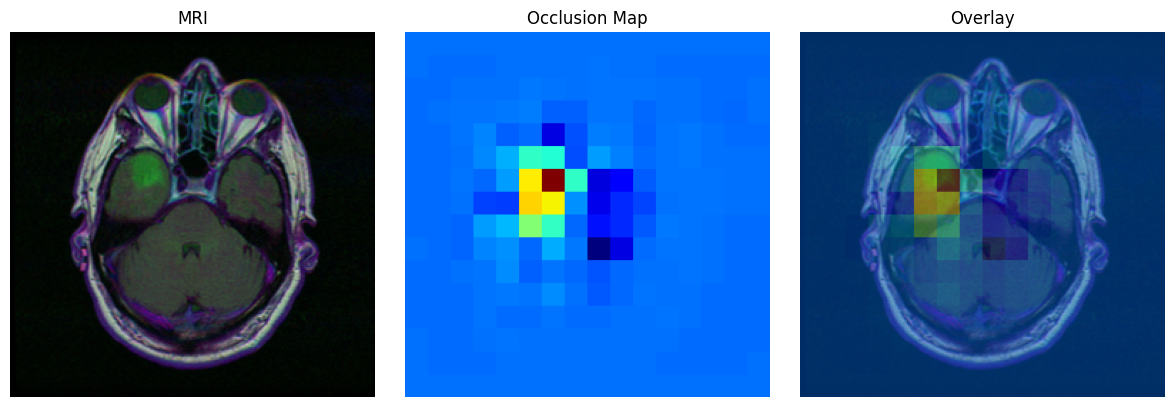

In [98]:
plt.figure(figsize=(12,4))

plt.subplot(1,3,1)
plt.imshow(img.squeeze().cpu().permute(1,2,0))
plt.title("MRI")
plt.axis("off")

plt.subplot(1,3,2)
plt.imshow(heatmap, cmap="jet")
plt.title("Occlusion Map")
plt.axis("off")

plt.subplot(1,3,3)
plt.imshow(img.squeeze().cpu().permute(1,2,0))
plt.imshow(heatmap, cmap="jet", alpha=0.4)
plt.title("Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()